# Градиентные каналы: отмеченное окно, прямоугольники и спектральные разладки

Используем локальную запись `data/excel-data/2085plus16GradOnly.xlsx`. В A находятся номера сенсоров, в B — имена каналов, в строке 1 — абсолютное время. **Все вычисления и графики ниже используют только интервал, отмеченный числовыми ячейками строки 206.** Нулевая отметка входит в окно; её физиологический смысл и единицы разметки не предполагаются. Обе крайние отмеченные ячейки включены. Никакие отсчёты за пределами этого окна не участвуют в спектральных оценках.

Сначала запускаем существующий `src.rectangle_segmentation.segment_pelt`, затем `src.oscillation_segmentation.segment_oscillations`, использующий общий `src.breakpoint_common.pelt_search`. Загрузка и визуализация вынесены в `utils/`, как в остальных экспериментах. Соглашение границ: `[start, end)`, внутренний индекс принадлежит правому сегменту; последний `n` — конец записи, а не разладка.

**Приватные результаты.** В Git хранится этот шаблон без выводов. Выполненная рабочая копия, таблицы и рисунки находятся в игнорируемом `experiments/gradient_window/`. Для повторного запуска из корня проекта:

```bash
source .venv/bin/activate
python -m jupyter nbconvert --to notebook --execute experiments/gradient_window.ipynb --output executed.ipynb --output-dir experiments/gradient_window --ExecutePreprocessor.timeout=600
```

Открывайте `experiments/gradient_window/executed.ipynb` для работы с результатами. Для интерактивного запуска шаблона сначала сохраните его копию в этой же игнорируемой папке. Файл данных должен быть предоставлен локально; загрузки из сети нет.

In [1]:
from pathlib import Path
import sys
import json
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / "src").is_dir() and (parent / "utils" / "paths.py").is_file()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from utils.paths import DATA_DIR, EXPERIMENTS_DIR
from utils.data_loading import load_xlsx_series
from src.rectangle_segmentation import segment_pelt
from src.oscillation_segmentation import segment_oscillations
from utils.rectangle_plots import plot_change_points, plot_rectangles
from utils.oscillation_plots import plot_oscillations

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
OUTPUT_DIR = EXPERIMENTS_DIR / "gradient_window"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## 1. Единое окно и параметры

Для воспроизводимого примера берём четыре канала, две пары по именам экспорта. Выбор фиксирован заранее и не основан на найденных разладках; `CHANNELS` можно заменить. Единицы амплитуды сохраняем как в файле, без недокументированного перевода в Тл/м.

Параметры задают исследовательский масштаб, а не обучены по разметке. Минимальная длительность — 0.5 с. У прямоугольников она относится к отсчётам, у спектрального метода — к числу последовательных шагов окон. Штрафы имеют разные функции стоимости и не являются общей шкалой качества.

In [19]:
DATA_FILE = DATA_DIR / "excel-data" / "2085plus16GradOnly.xlsx"
CHANNELS = ["MEG0112", "MEG1432", "MEG2023", "MEG2443"]
WINDOW_ROW = 206
MIN_DURATION_S = 0.5
RECTANGLE_PENALTY = 0.02
SPECTRAL_PENALTY = 0.002
SPECTRAL_OPTIONS = dict(
    window_seconds=0.4, step_seconds=0.05, min_duration=MIN_DURATION_S,
    frequency_band=(2.0, 100.0), amplitude_weight=1.0, frequency_weight=1.0,
)

if not DATA_FILE.is_file():
    raise FileNotFoundError(f"Поместите приватный Excel локально: {DATA_FILE}")
series = load_xlsx_series(DATA_FILE, channel_names=CHANNELS, window_row=WINDOW_ROW)
for s in series:
    np.testing.assert_array_equal(s["times"], series[0]["times"])
    np.testing.assert_array_equal(s["window_values"], series[0]["window_values"])

sampling = pd.DataFrame([
    dict(channel=s["channel_name"], sensor_id=s["sensor_id"], n_samples=len(s["signal"]),
         sfreq_hz=s["sfreq"], first_time_s=s["times"][0], last_time_s=s["times"][-1],
         first_source_sample=s["sample_start"], stop_source_sample=s["sample_stop"],
         first_annotation=s["window_values"][0], last_annotation=s["window_values"][-1])
    for s in series
])
display(sampling)

,channel,sensor_id,n_samples,sfreq_hz,first_time_s,last_time_s,first_source_sample,stop_source_sample,first_annotation,last_annotation
0,MEG0112,1.2,5001,1000.0,2087.844,2092.844,2844,7845,-1000.0,4000.0
1,MEG1432,53.2,5001,1000.0,2087.844,2092.844,2844,7845,-1000.0,4000.0
2,MEG2023,76.3,5001,1000.0,2087.844,2092.844,2844,7845,-1000.0,4000.0
3,MEG2443,94.3,5001,1000.0,2087.844,2092.844,2844,7845,-1000.0,4000.0


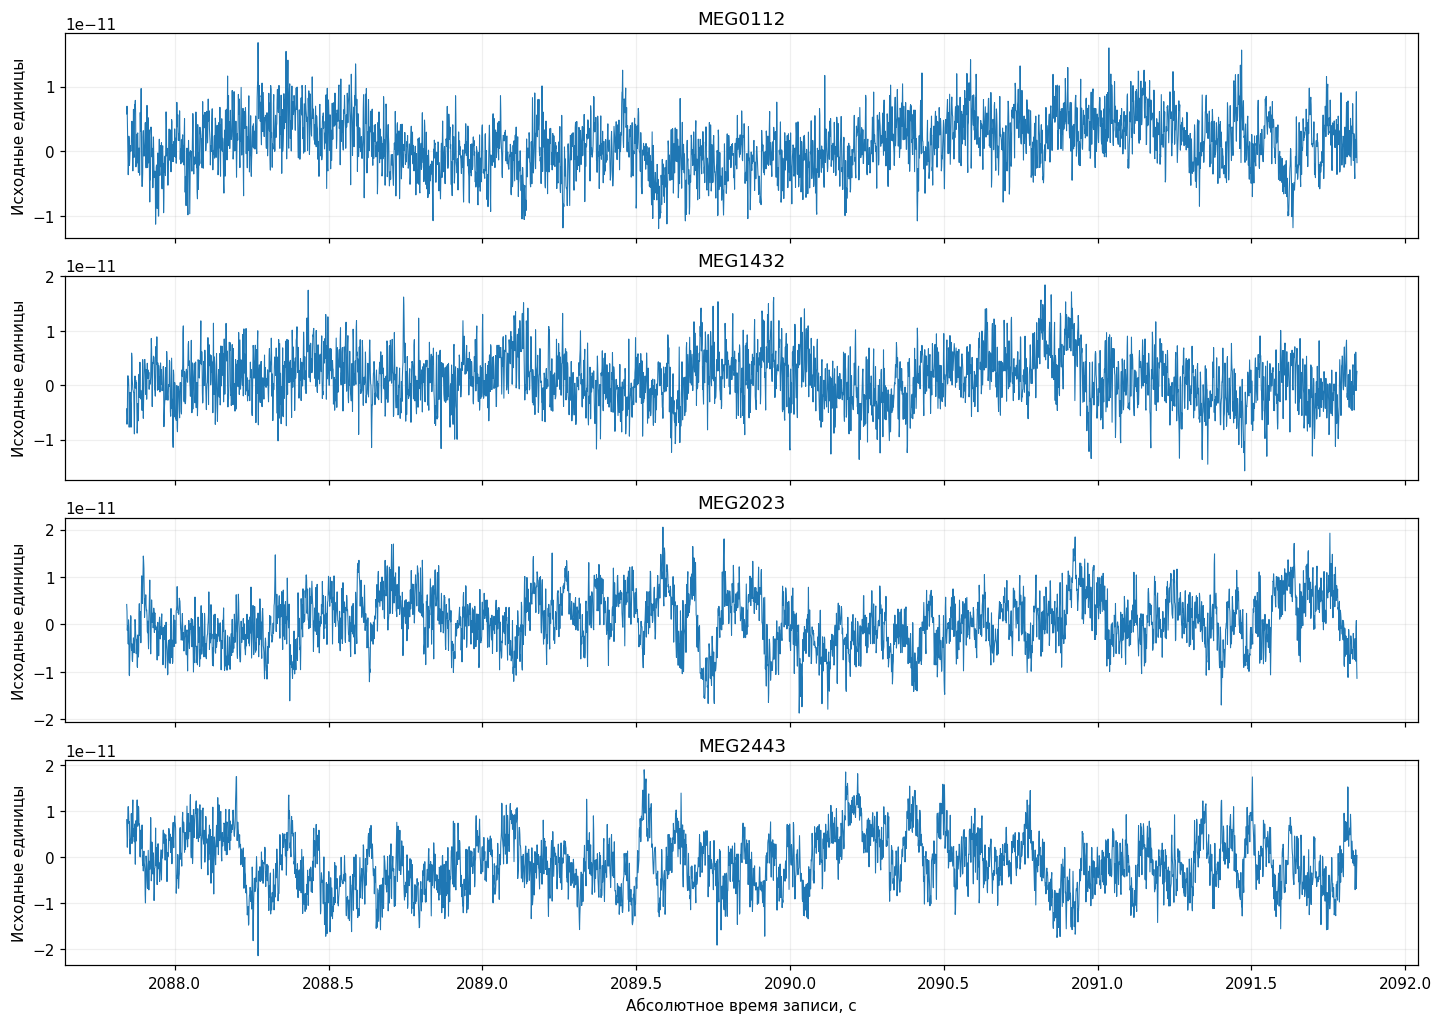

In [14]:
fig, axes = plt.subplots(len(series), 1, figsize=(13, 2.3*len(series)), sharex=True, layout="constrained")
for ax, s in zip(np.atleast_1d(axes), series):
    ax.plot(s["times"][:4000], s["signal"][:4000], lw=0.7)
    ax.set(ylabel="Исходные единицы", title=s["channel_name"])
    ax.grid(alpha=0.2)
axes[-1].set_xlabel("Абсолютное время записи, с")
fig.savefig(OUTPUT_DIR / "selected_window.png", dpi=130)
plt.show()

## 2. Метод прямоугольников с PELT

Без сглаживания и изменения частоты дискретизации используем существующий критерий

$$J(B)=\sum_{[s,e)\in B}\frac{(e-s)(\max y_{s:e}-\min y_{s:e})}{n(\max y-\min y)}+\beta k.$$

PELT проверяет все допустимые позиции исходного ряда. Прямоугольник характеризует диапазон амплитуд участка. При неизменной амплитуде смена частоты может почти не менять эту стоимость; отдельные циклы или выбросы также могут создавать границы.

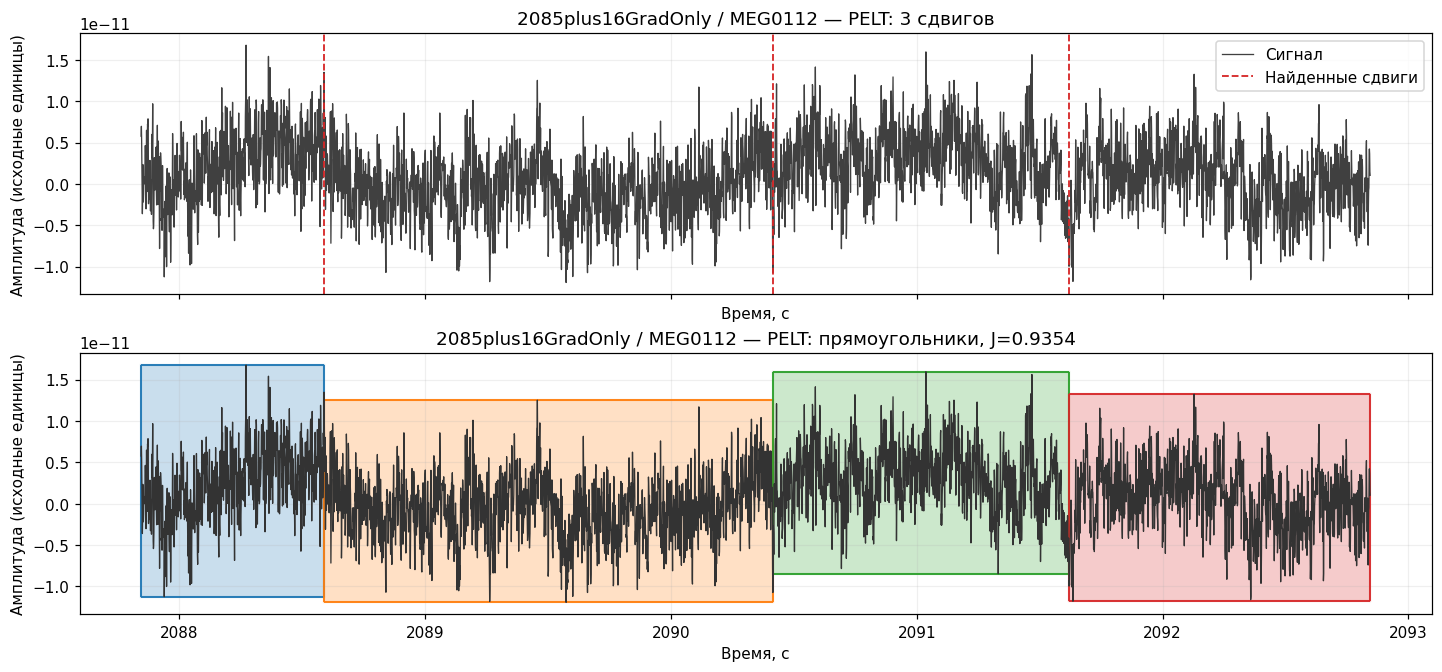

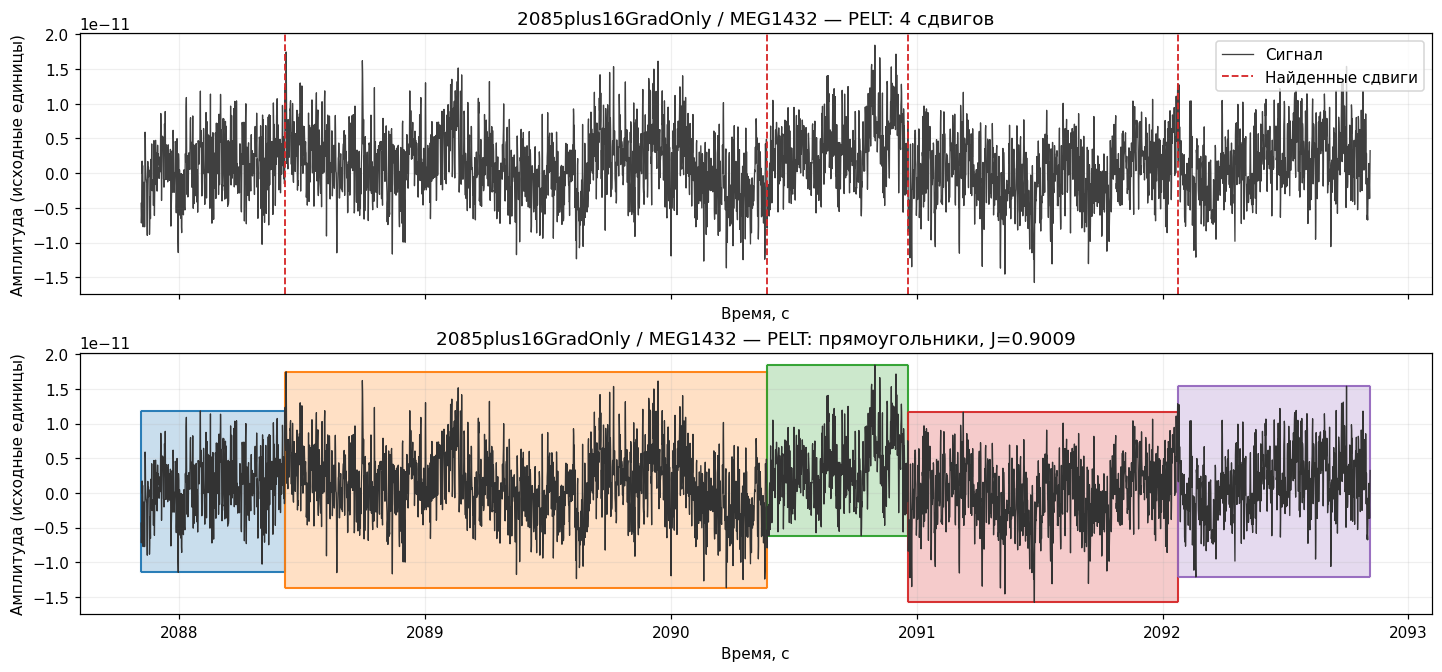

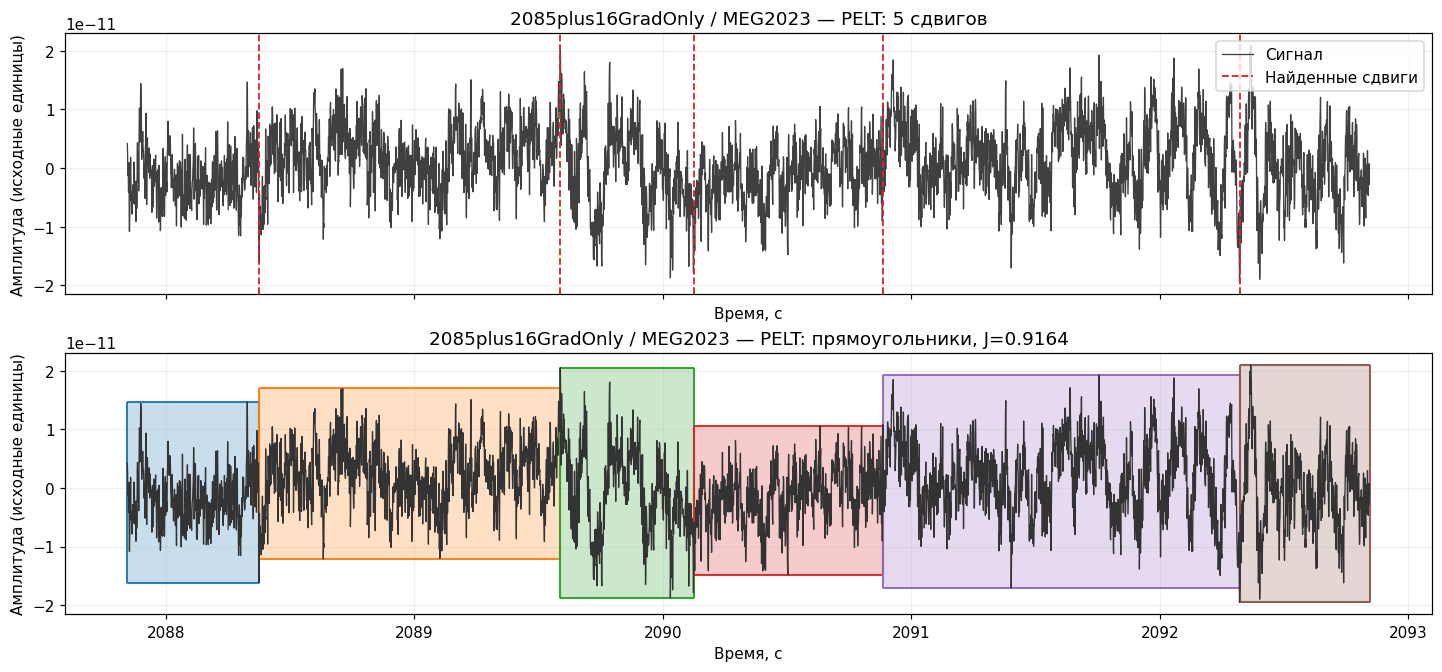

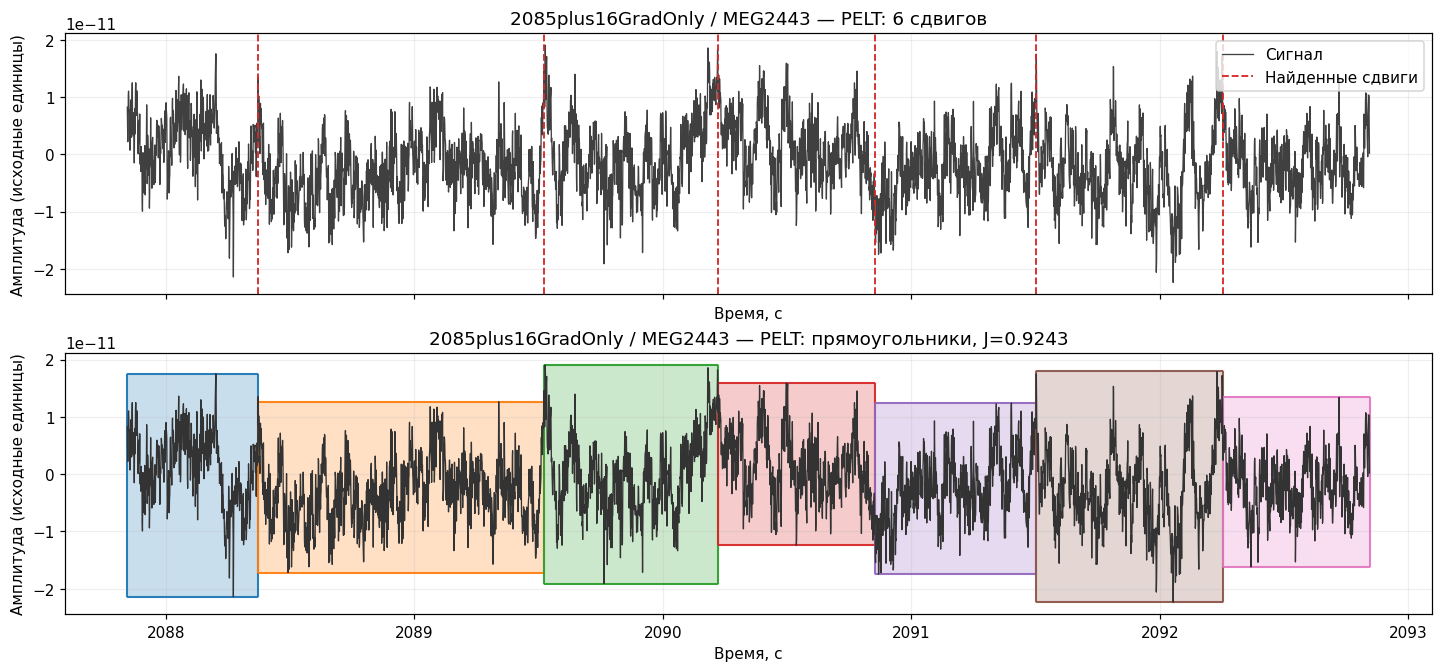

In [15]:
rectangle_results = [
    segment_pelt(s["signal"], penalty=RECTANGLE_PENALTY,
                 min_size=int(np.ceil(MIN_DURATION_S*s["sfreq"] - 1e-8)))
    for s in series
]
for s, result in zip(series, rectangle_results):
    fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True, layout="constrained")
    plot_change_points(s, result, ax=axes[0])
    plot_rectangles(s, result, ax=axes[1])
    fig.savefig(OUTPUT_DIR / f"rectangles_{s['channel_name']}.png", dpi=130)
    plt.show()

## 3. Разладки амплитуды и частотного состава

Для каждого полного окна длиной 0.4 с с шагом 0.05 с удаляем среднее и вычисляем периодограмму с окном Hann. В полосе 2–100 Гц получаем RMS $A=\sqrt{\sum_f P_f\Delta f}$ и нормированные мощности $p_f=P_f/\sum_fP_f$. Амплитуда RMS отличается от пиковой амплитуды синусоиды в $\sqrt{2}$ раза. Пик и центр мощности спектра показываем для интерпретации; детектор использует **всю форму спектра**, а не только максимум.

Признаки: $x=[\sqrt{w_A}\log_2(A/A_{ref}),\sqrt{w_f}\sqrt{p_1},\ldots]$, где $A_{ref}$ — максимальная RMS среди окон этого канала. Штрафуем изменения среднего этих признаков:

$$J(B)=\frac{1}{M}\sum_{[s,e)\in B}\sum_{j=s}^{e-1}\|x_j-\bar x_{s:e}\|^2+\beta k.$$

Удвоение амплитуды даёт единичный шаг логарифмического признака; спектральный блок отделён от общего уровня мощности. Отдельные частотные бины не стандартизуются по дисперсии. Два веса задают относительный вклад механизмов. У почти нулевых окон логарифм ограничен снизу уровнем $10^{-12}$ от максимальной RMS, а частота считается неопределённой.

PELT оптимизирует критерий на сетке окон. Границу между двумя оконными режимами переносим в ближайший исходный отсчёт к середине между центрами соседних окон. **Шаг сетки 50 мс не означает точность 50 мс:** переход размывается окном примерно на ±0.2 с; шаг частотных бинов около 2.5 Гц, фактическое разрешение также зависит от Hann. Режимы короче окна трудно разделить. Оконные оценки по краям отсутствуют; хвост короче шага наследует последний режим. Метод обрабатывает уже записанный фрагмент целиком и не является онлайн-детектором.

Описание [периодограммы SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.periodogram.html) и [стоимости L2](https://centre-borelli.github.io/ruptures-docs/user-guide/costs/costl2/). Комбинация признаков выше — выбранная здесь исследовательская постановка.

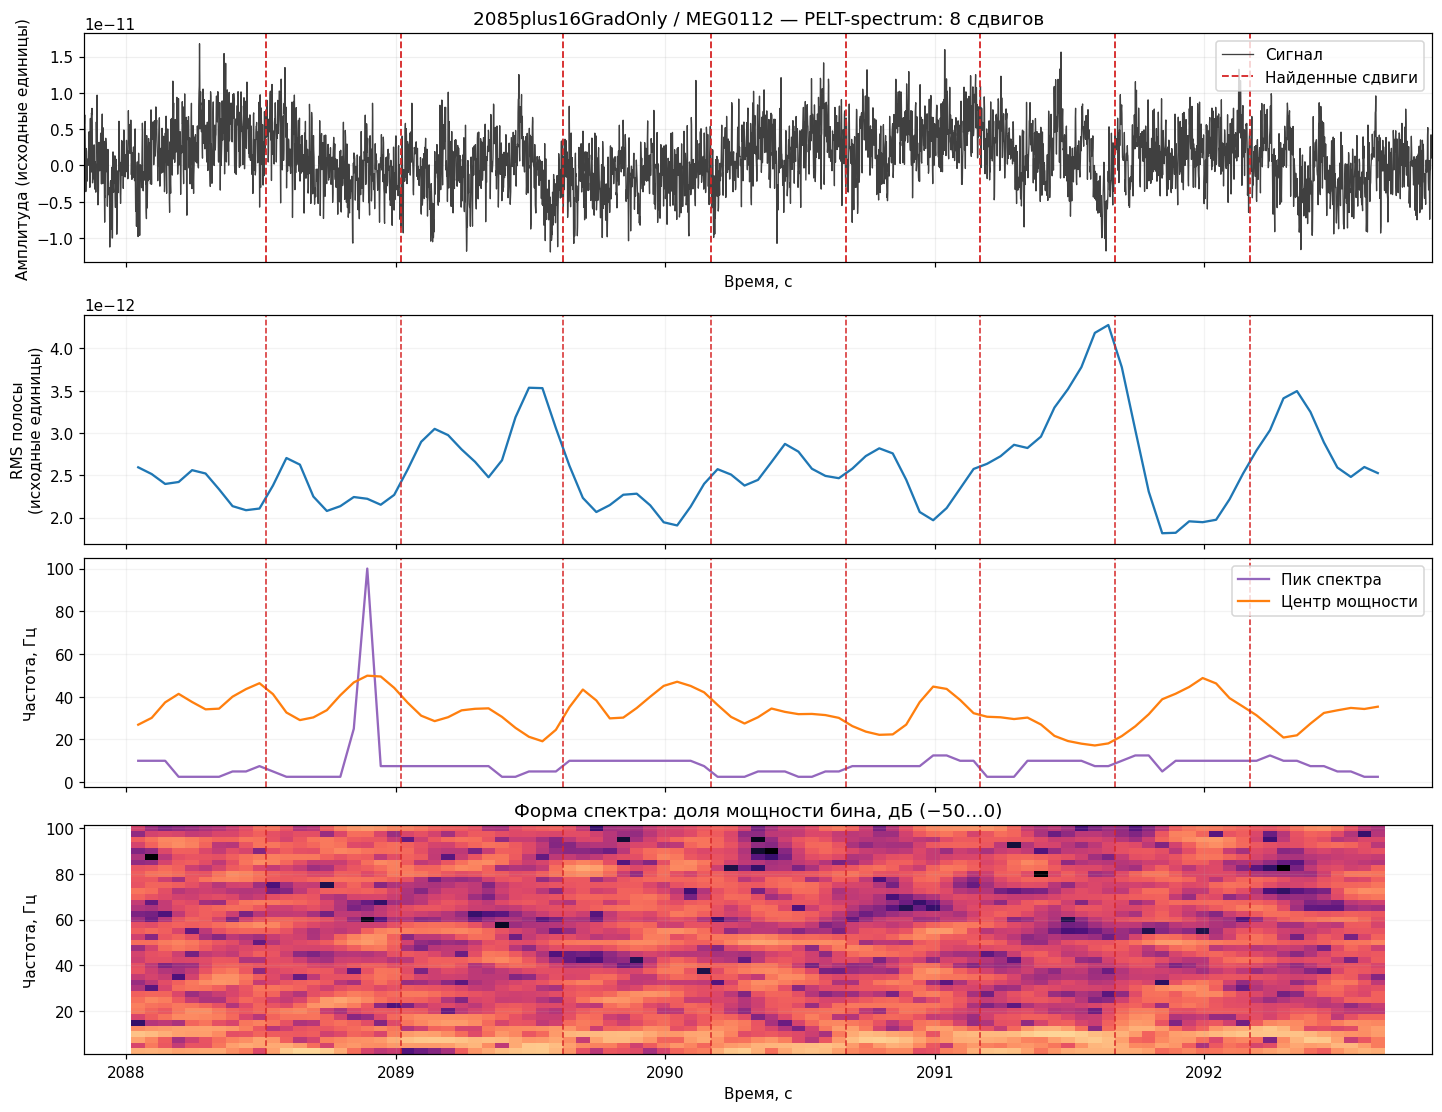

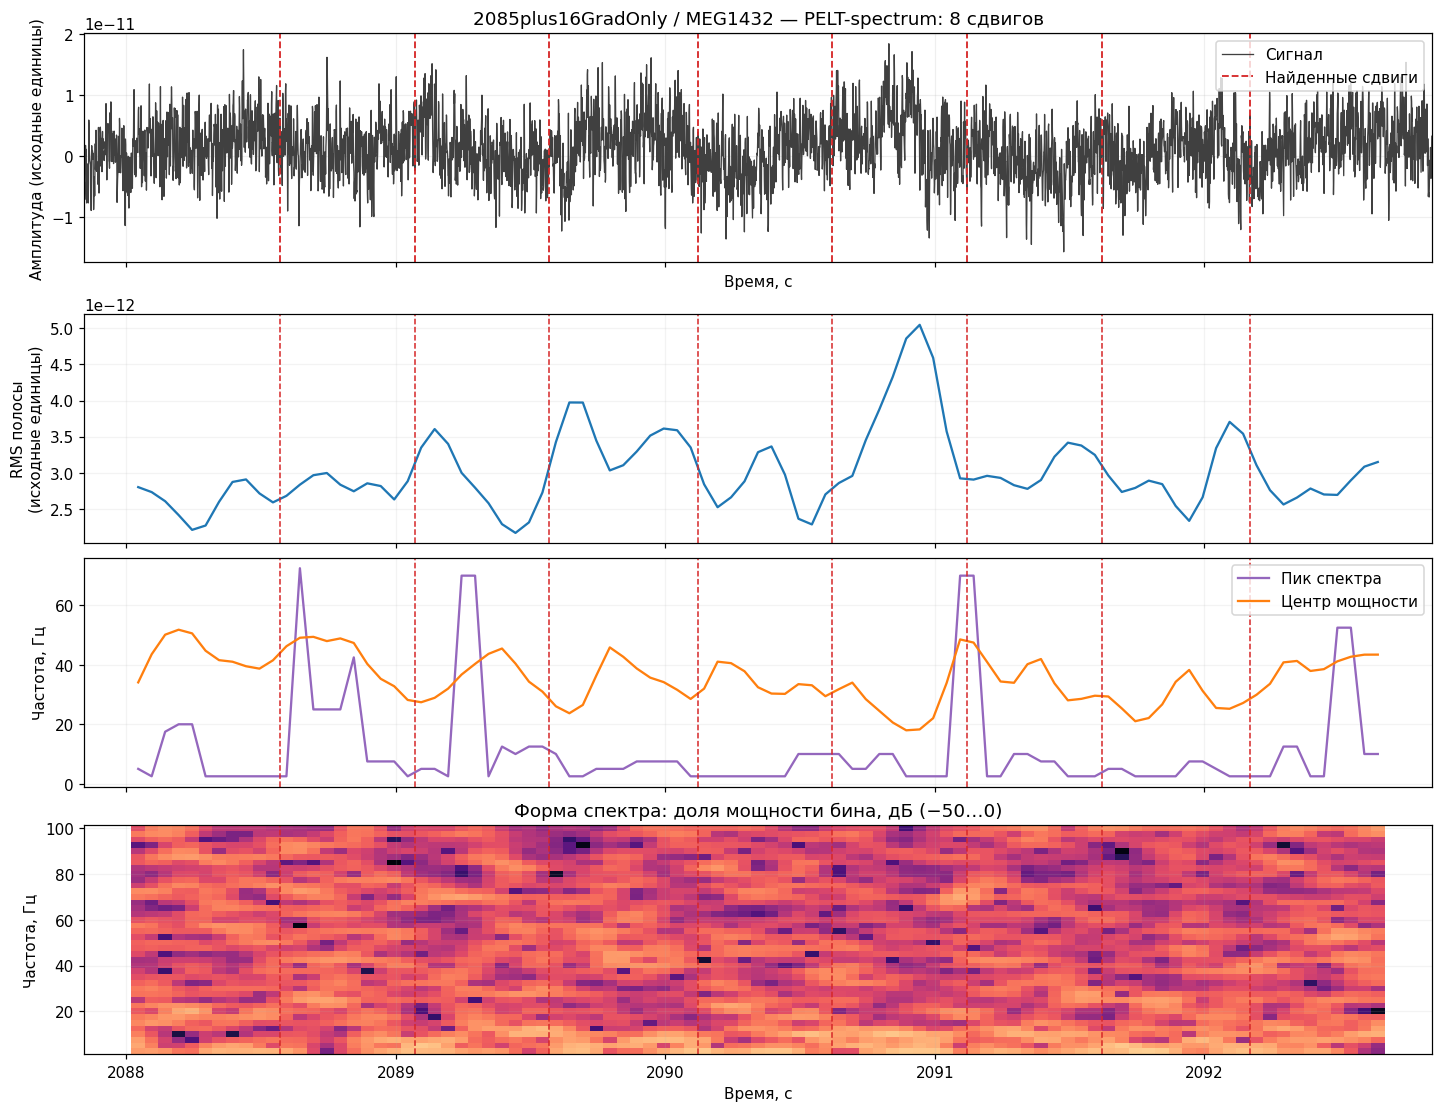

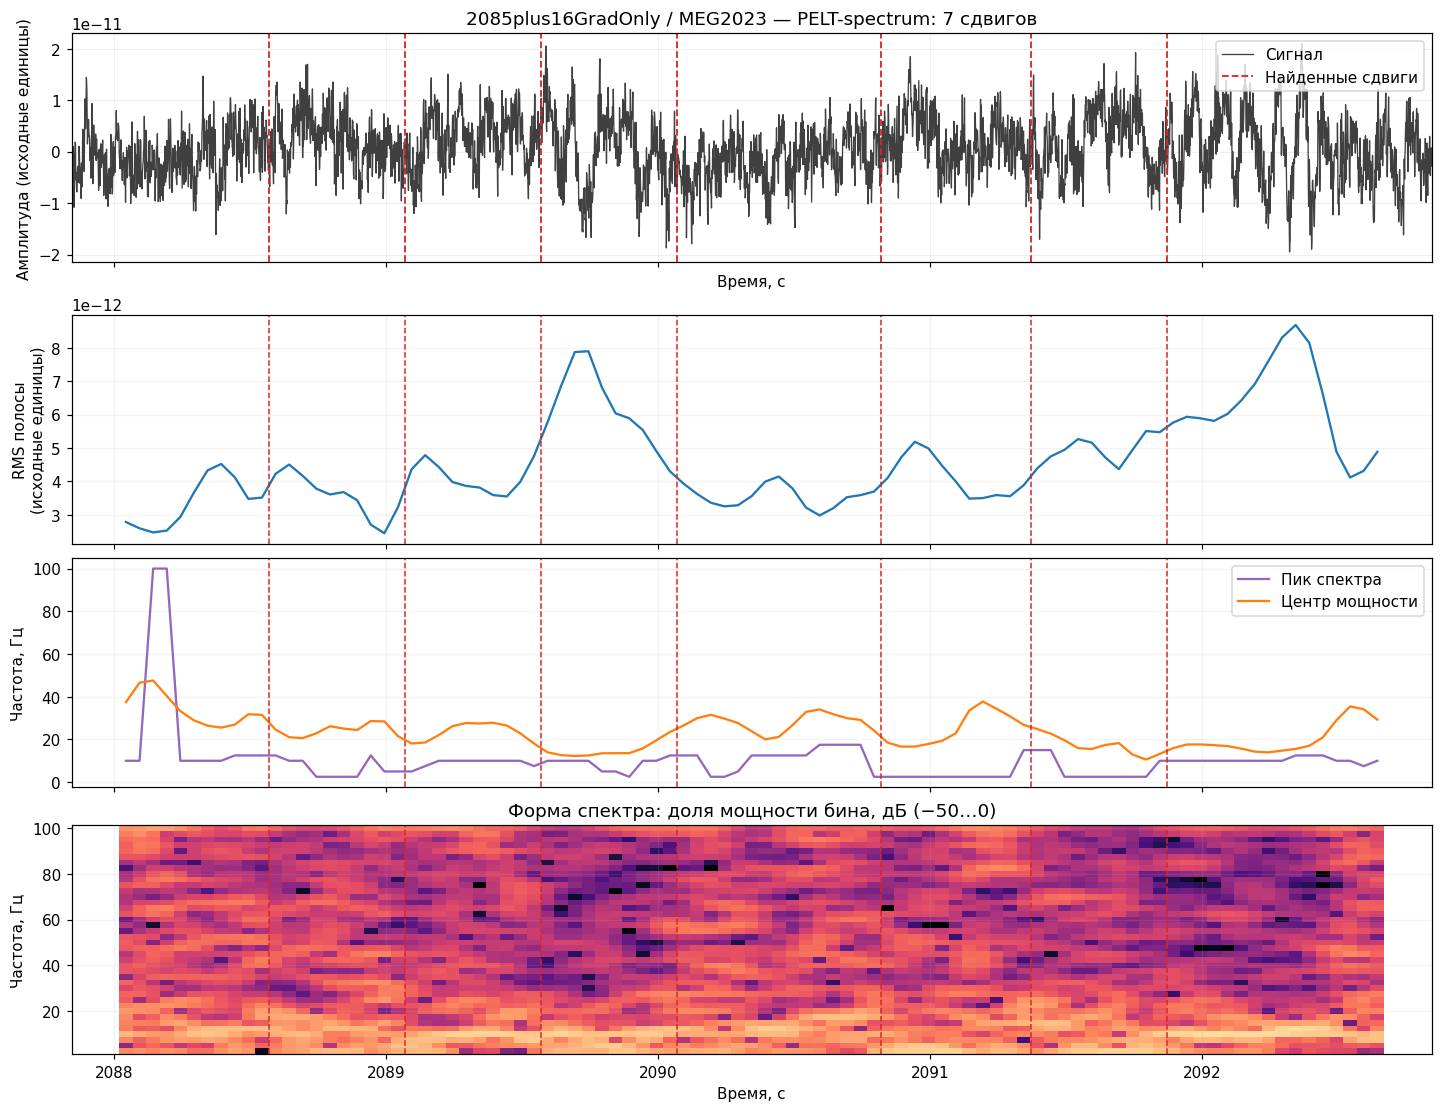

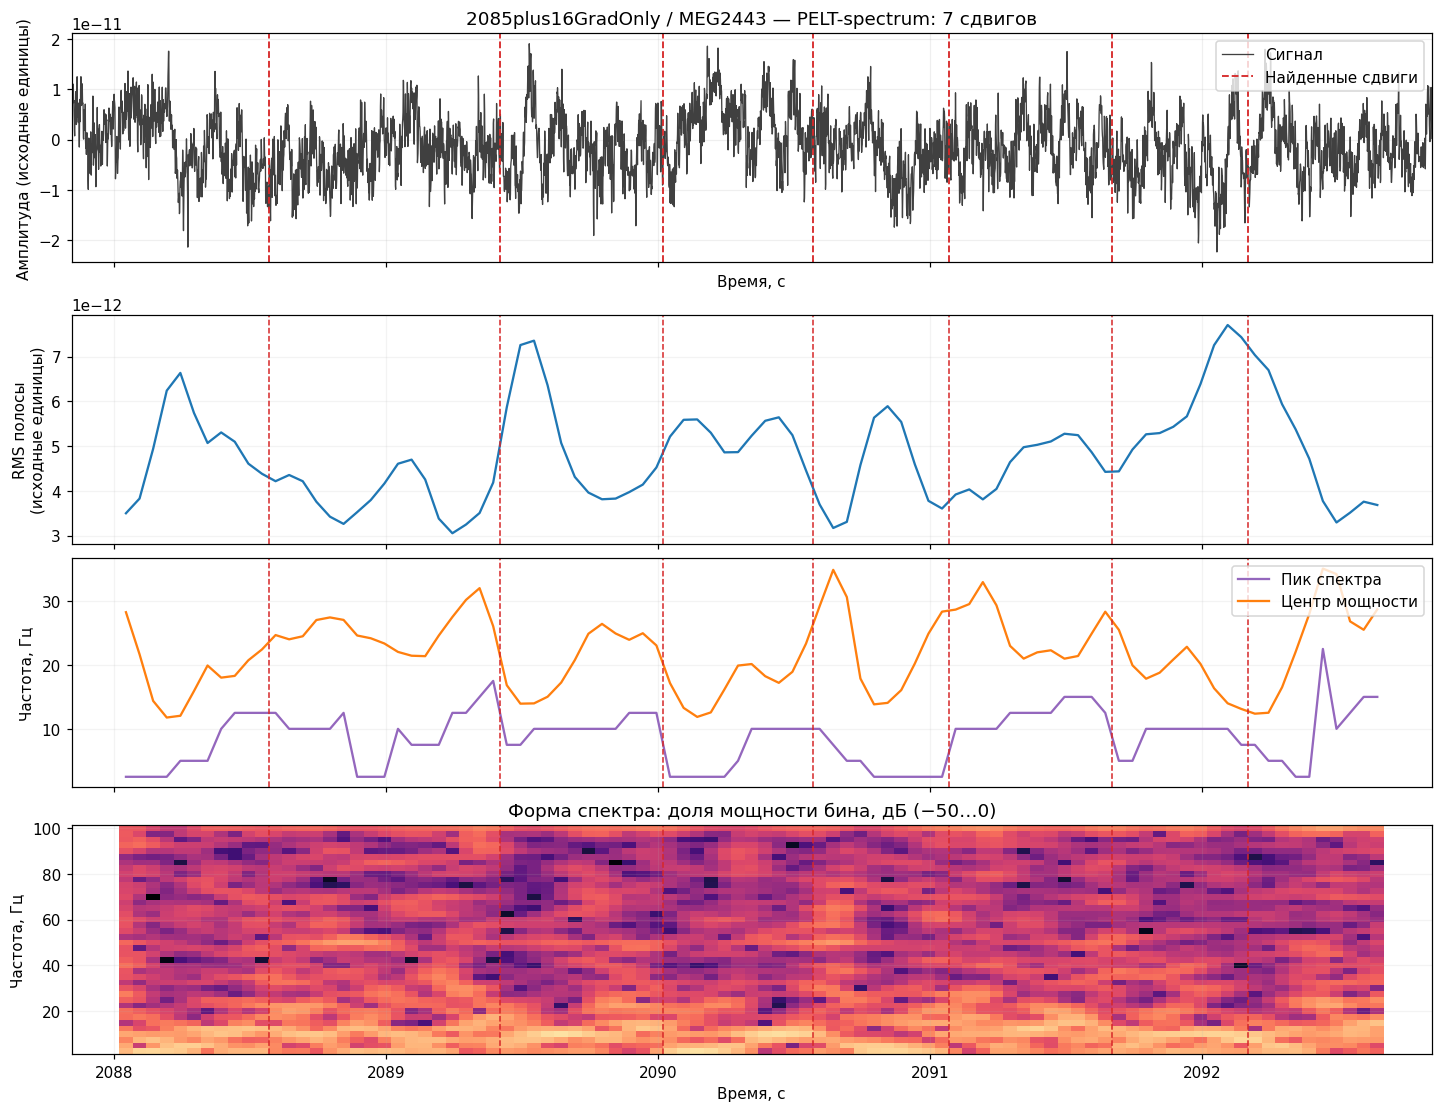

,channel,frames,window_s,step_s,min_frames,bin_step_hz,uncovered_tail_samples
0,MEG0112,93,0.4,0.05,10,2.5,1
1,MEG1432,93,0.4,0.05,10,2.5,1
2,MEG2023,93,0.4,0.05,10,2.5,1
3,MEG2443,93,0.4,0.05,10,2.5,1


In [20]:
spectral_results = [
    segment_oscillations(s["signal"], s["sfreq"], penalty=SPECTRAL_PENALTY,
                         times=s["times"], **SPECTRAL_OPTIONS)
    for s in series
]
for s, result in zip(series, spectral_results):
    fig, _ = plot_oscillations(s, result)
    fig.savefig(OUTPUT_DIR / f"spectrum_{s['channel_name']}.png", dpi=130)
    plt.show()

display(pd.DataFrame([
    dict(channel=s["channel_name"], frames=len(r.diagnostics["frame_times"]),
         window_s=r.params["window_seconds"], step_s=r.params["step_seconds"],
         min_frames=r.params["min_frames"], bin_step_hz=r.diagnostics["frequency_resolution_hz"],
         uncovered_tail_samples=r.diagnostics["uncovered_tail_samples"])
    for s, r in zip(series, spectral_results)
]))

## 4. Границы и свойства спектральных режимов

Все индексы с нуля. `sample_in_window` относится к обрезанному ряду, `sample_in_recording` — к полной записи; `excel_column` учитывает два столбца метаданных и нумерацию Excel с единицы. Времена сохраняют систему координат исходной таблицы. Строка 206 описывает выбранное окно и не считается истинной разметкой разладок.

In [17]:
summary_rows, boundary_rows, regime_rows = [], [], []
for s, rectangle, spectral in zip(series, rectangle_results, spectral_results):
    for method, result in [("Прямоугольники", rectangle), ("Спектр + амплитуда", spectral)]:
        summary_rows.append(dict(channel=s["channel_name"], method=method,
                                 n_changes=len(result.change_points), objective=result.objective,
                                 penalty=result.penalty, elapsed_s=result.elapsed_seconds,
                                 break_times_s=s["times"][result.change_points].tolist()))
        for b in result.change_points:
            boundary_rows.append(dict(channel=s["channel_name"], method=method,
                                      sample_in_window=b, sample_in_recording=s["sample_start"]+b,
                                      excel_column=s["sample_start"]+b+3,
                                      time_s=s["times"][b], annotation=s["window_values"][b]))
    d = spectral.diagnostics
    sample_start, frame_start = 0, 0
    for sample_stop, frame_stop in zip(spectral.breakpoints, d["frame_breakpoints"]):
        frame_slice = slice(frame_start, frame_stop)
        regime_rows.append(dict(channel=s["channel_name"], start_sample=sample_start, stop_sample=sample_stop,
                                start_time_s=s["times"][sample_start],
                                stop_time_s=(s["times"][sample_stop] if sample_stop < len(s["signal"])
                                             else s["times"][-1]+1/s["sfreq"]),
                                median_band_rms=np.median(d["band_rms"][frame_slice]),
                                median_peak_hz=np.median(d["peak_hz"][frame_slice]),
                                median_centroid_hz=np.median(d["centroid_hz"][frame_slice])))
        sample_start, frame_start = sample_stop, frame_stop
summary = pd.DataFrame(summary_rows)
boundaries = pd.DataFrame(boundary_rows, columns=[
    "channel", "method", "sample_in_window", "sample_in_recording", "excel_column", "time_s", "annotation"])
regimes = pd.DataFrame(regime_rows)
display(summary)
display(boundaries)
display(regimes)

,channel,method,n_changes,objective,penalty,elapsed_s,break_times_s
0,MEG0112,Прямоугольники,3,0.935409,0.02,0.412002,"[2088.589, 2090.415, 2091.619]"
1,MEG0112,Спектр + амплитуда,0,0.264103,0.02,0.040802,[]
2,MEG1432,Прямоугольники,4,0.900862,0.02,0.349554,"[2088.43, 2090.392, 2090.965, 2092.061]"
3,MEG1432,Спектр + амплитуда,1,0.243901,0.02,0.016958,[2088.869]
4,MEG2023,Прямоугольники,5,0.916445,0.02,0.301584,"[2088.375, 2089.586, 2090.124, 2090.885, 2092...."
5,MEG2023,Спектр + амплитуда,3,0.278714,0.02,0.013868,"[2089.519, 2090.019, 2091.769]"
6,MEG2443,Прямоугольники,6,0.924267,0.02,0.362106,"[2088.372, 2089.521, 2090.221, 2090.855, 2091...."
7,MEG2443,Спектр + амплитуда,0,0.277399,0.02,0.012075,[]


,channel,method,sample_in_window,sample_in_recording,excel_column,time_s,annotation
0,MEG0112,Прямоугольники,745,3589,3592,2088.589,-255.0
1,MEG0112,Прямоугольники,2571,5415,5418,2090.415,1571.0
2,MEG0112,Прямоугольники,3775,6619,6622,2091.619,2775.0
3,MEG1432,Прямоугольники,586,3430,3433,2088.430,-414.0
4,MEG1432,Прямоугольники,2548,5392,5395,2090.392,1548.0
5,MEG1432,Прямоугольники,3121,5965,5968,2090.965,2121.0
6,MEG1432,Прямоугольники,4217,7061,7064,2092.061,3217.0
7,MEG1432,Спектр + амплитуда,1025,3869,3872,2088.869,25.0
8,MEG2023,Прямоугольники,531,3375,3378,2088.375,-469.0
9,MEG2023,Прямоугольники,1742,4586,4589,2089.586,742.0


,channel,start_sample,stop_sample,start_time_s,stop_time_s,median_band_rms,median_peak_hz,median_centroid_hz
0,MEG0112,0,5001,2087.844,2092.845,2.525956e-12,7.5,32.599666
1,MEG1432,0,1025,2087.844,2088.869,2.731952e-12,5.0,46.253645
2,MEG1432,1025,5001,2088.869,2092.845,2.942709e-12,5.0,33.564272
3,MEG2023,0,1675,2087.844,2089.519,3.671692e-12,10.0,26.455112
4,MEG2023,1675,2175,2089.519,2090.019,5.962372e-12,10.0,13.553749
5,MEG2023,2175,3925,2090.019,2091.769,3.929807e-12,2.5,24.153348
6,MEG2023,3925,5001,2091.769,2092.845,5.909740e-12,10.0,16.940946
7,MEG2443,0,5001,2087.844,2092.845,4.639927e-12,10.0,21.967220


## 5. Чувствительность и вклад признаков

На том же выбранном окне первого канала проверяем половинный, основной и удвоенный штраф. Для спектрального метода дополнительно отключаем по одному блоку признаков. Эти запуски помогают понять влияние настроек, но не устанавливают причину каждой разладки. Основные результаты выше остаются с заранее заданными параметрами.

In [18]:
s = series[0]
sensitivity_rows = []
for factor in [0.5, 1.0, 2.0]:
    rect = (rectangle_results[0] if factor == 1 else segment_pelt(
        s["signal"], penalty=RECTANGLE_PENALTY*factor, min_size=rectangle_results[0].min_size))
    spectral = (spectral_results[0] if factor == 1 else segment_oscillations(
        s["signal"], s["sfreq"], penalty=SPECTRAL_PENALTY*factor, times=s["times"], **SPECTRAL_OPTIONS))
    for method, result in [("Прямоугольники", rect), ("Спектр + амплитуда", spectral)]:
        sensitivity_rows.append(dict(method=method, penalty=result.penalty,
                                     n_changes=len(result.change_points),
                                     break_times_s=s["times"][result.change_points].tolist()))
for label, weights in [("Только амплитуда", dict(frequency_weight=0.0)),
                       ("Только форма спектра", dict(amplitude_weight=0.0))]:
    options = SPECTRAL_OPTIONS | weights
    result = segment_oscillations(s["signal"], s["sfreq"], penalty=SPECTRAL_PENALTY,
                                 times=s["times"], **options)
    sensitivity_rows.append(dict(method=label, penalty=result.penalty,
                                 n_changes=len(result.change_points),
                                 break_times_s=s["times"][result.change_points].tolist()))
sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity)

,method,penalty,n_changes,break_times_s
0,Прямоугольники,0.01,7,"[2088.624, 2089.17, 2089.67, 2090.415, 2091.03..."
1,Спектр + амплитуда,0.01,6,"[2089.019, 2089.619, 2090.169, 2090.669, 2091...."
2,Прямоугольники,0.02,3,"[2088.589, 2090.415, 2091.619]"
3,Спектр + амплитуда,0.02,0,[]
4,Прямоугольники,0.04,3,"[2088.589, 2090.415, 2091.619]"
5,Спектр + амплитуда,0.04,0,[]
6,Только амплитуда,0.02,0,[]
7,Только форма спектра,0.02,0,[]


## 6. Локальное сохранение и интерпретация

Сохраняем таблицы и параметры в игнорируемую папку этого эксперимента. Сходство границ двух методов — согласованность, не оценка точности. Истинных границ нет, поэтому F1 не вычисляется. Смена спектра может отражать шум, артефакт или колебательный режим; автоматической физиологической интерпретации здесь нет. Полоса включает сетевую частоту 50 Гц: фильтрация и удаление артефактов не выполнялись. Анализ ограничен заданной полосой; изменения за её пределами могут быть пропущены.

Алгоритмические проверки находятся в `tests/test_gradient_window.py` и `tests/test_oscillation_segmentation.py`: искусственные Excel-файлы, независимый перебор сегментаций, отдельные смены частоты/амплитуды, стационарные сигналы, масштабы МЭГ и перенос границ во время. Проверки не используют приватную запись.

In [8]:
for name, table in [("sampling", sampling), ("summary", summary), ("boundaries", boundaries),
                    ("spectral_regimes", regimes), ("sensitivity", sensitivity)]:
    table.to_csv(OUTPUT_DIR / f"{name}.csv", index=False)
manifest = dict(
    data_file=DATA_FILE.name, window_row=WINDOW_ROW, channels=CHANNELS,
    source_sample_start=series[0]["sample_start"], source_sample_stop=series[0]["sample_stop"],
    rectangle_penalty=RECTANGLE_PENALTY, rectangle_min_size=rectangle_results[0].min_size,
    spectral_penalty=SPECTRAL_PENALTY, spectral_params=spectral_results[0].params,
    versions={name: version(name) for name in ["numpy", "scipy", "openpyxl", "matplotlib", "pandas"]},
)
(OUTPUT_DIR / "manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Локальные результаты: {OUTPUT_DIR}")

Локальные результаты: /home/nikita/git/brain_breaks/experiments/gradient_window
